In [29]:
import re
import numpy as np
import matplotlib.pyplot as plt

In [30]:
# Load All Data
data_fname = '../spreadsheet_20261012.csv'
header = ["temp","eps12","L1","N1","L2","N2","M2",
          "block_size", "start_frame",
          "K2","log_K2", "SEM_K2", "SEM_log_K2",
          "phi_all_dense","phi_all_dilute","phi1_dense","phi1_dilute","phi2_dense","phi2_dilute",
          "SEM_phi_all_dense", "SEM_phi_all_dilute", "SEM_phi1_dense", "SEM_phi1_dilute", "SEM_phi2_dense", "SEM_phi2_dilute",
          "rho_all_dense","rho_all_dilute","rho1_dense","rho1_dilute","rho2_dense","rho2_dilute",
          "SEM_rho_all_dense", "SEM_rho_all_dilute", "SEM_rho1_dense", "SEM_rho1_dilute", "SEM_rho2_dense", "SEM_rho2_dilute"]
data = np.genfromtxt(data_fname, delimiter=",", names=True)
temp, eps12 = data['temp'], data['eps12']
L1, N1, L2, N2, M2 = data['L1'], data['N1'], data['L2'], data['N2'], data['M2']
mean_dense_rho, mean_dilute_rho = data['rho2_dense'], data['rho2_dilute']
K2, logK2 = data['K2'], data['log_K2']

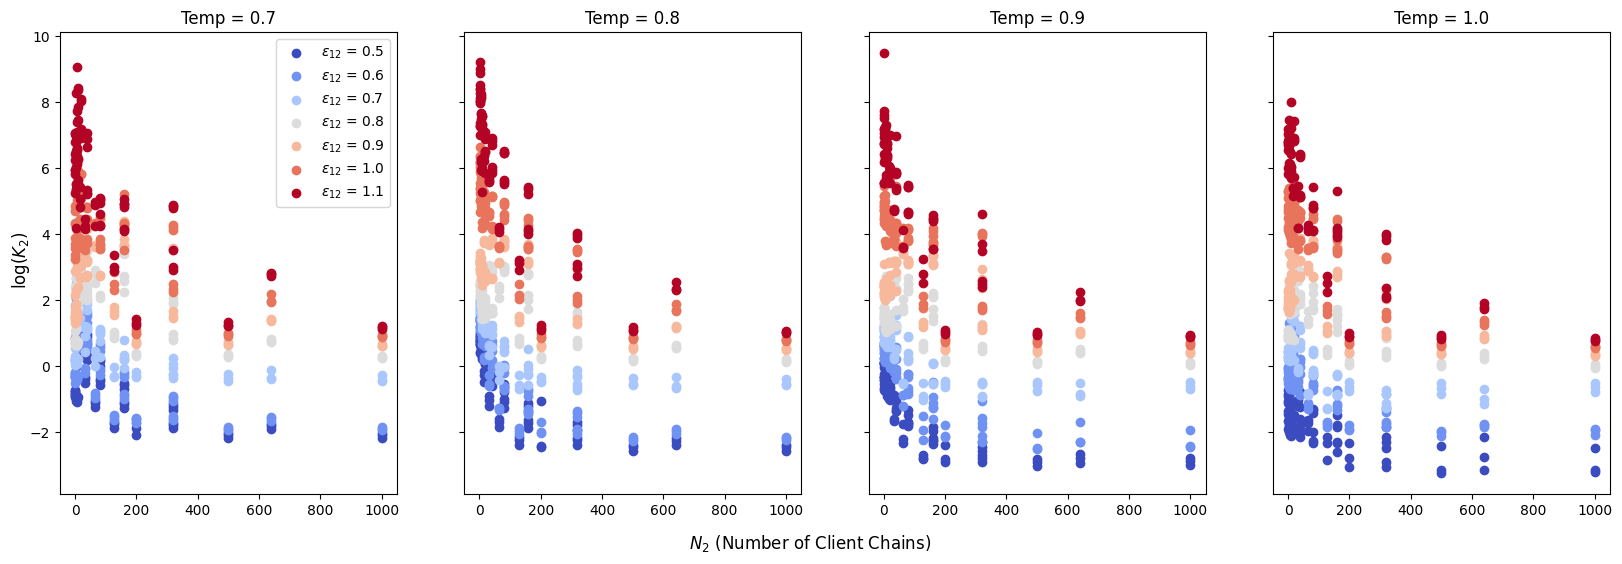

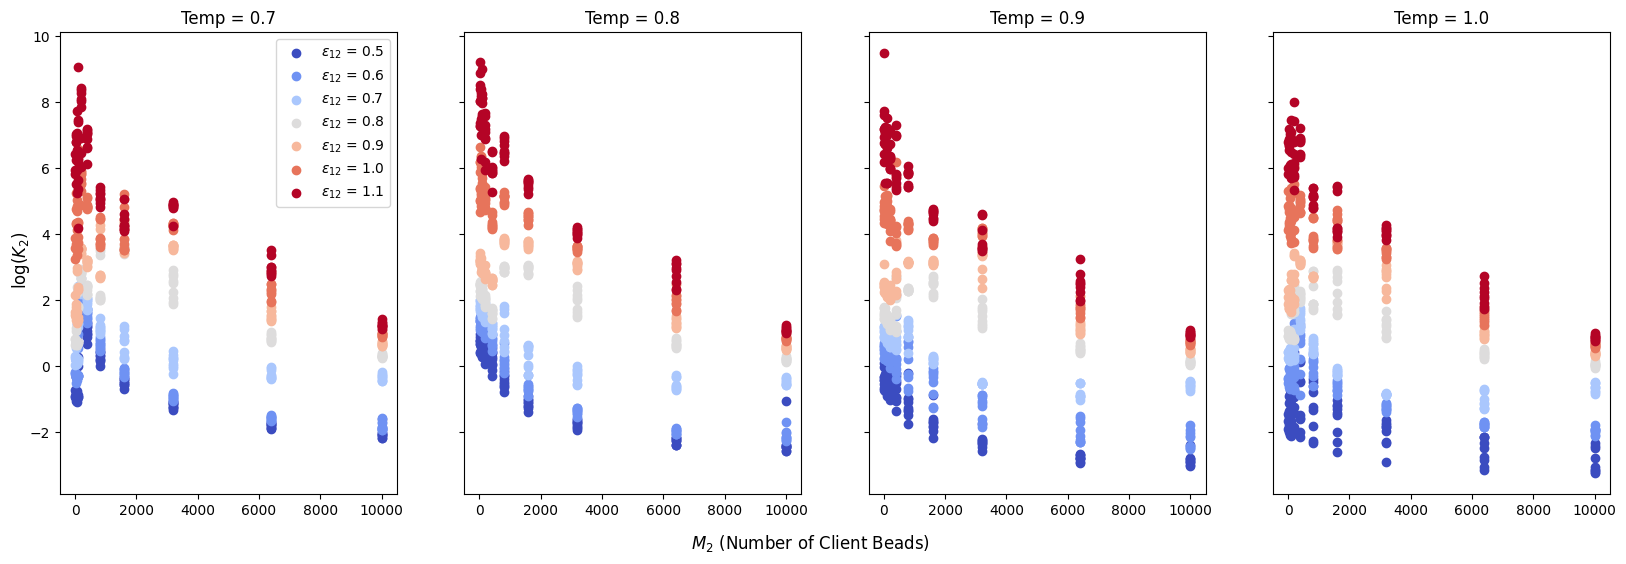

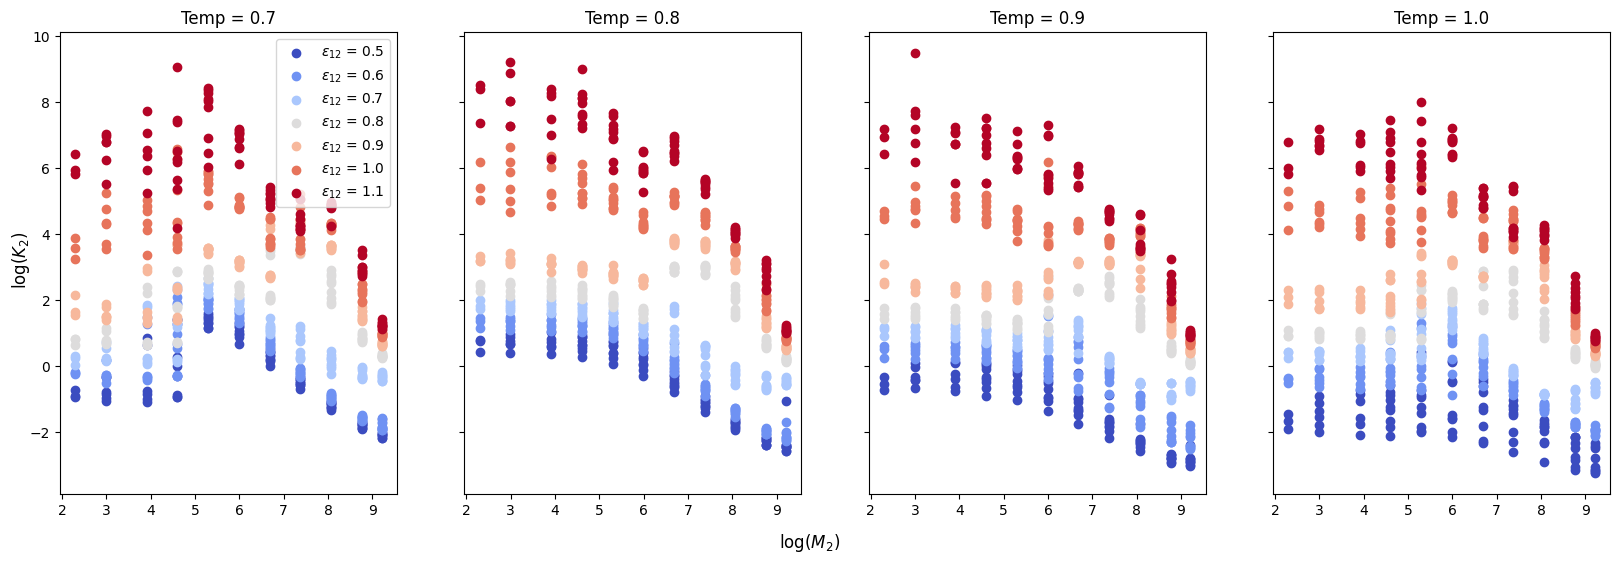

In [36]:
## Plotting N2/M2 vs. log(K2)
temperatures = [0.7, 0.8, 0.9, 1.0]
eps12_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(eps12_values)))
fig1, axes1 = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
fig2, axes2 = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
fig3, axes3 = plt.subplots(1, 4, figsize=(20, 6), sharey=True)
for i, temp_screen in enumerate(temperatures):
    ax1 = axes1[i]
    ax2 = axes2[i]
    ax3 = axes3[i]
    
    for eps, edge in zip(eps12_values, edgecols):
        mask = np.where( (temp == temp_screen) & (eps12 == eps) )
        ax1.scatter(N2[mask], logK2[mask], label=rf'$\epsilon_{{12}}$ = {eps}', color=edge)
        ax1.set_title(f'Temp = {temp_screen}')
    
        ax2.scatter(M2[mask], logK2[mask], label=rf'$\epsilon_{{12}}$ = {eps}', color=edge)
        ax2.set_title(f'Temp = {temp_screen}')

        ax3.scatter(np.log(M2[mask]), logK2[mask], label=rf'$\epsilon_{{12}}$ = {eps}', color=edge)
        ax3.set_title(f'Temp = {temp_screen}')
    if i == 0:
        ax1.legend()
        ax2.legend()
        ax3.legend()

fig1.supxlabel(r'$N_2$ (Number of Client Chains)')
fig1.supylabel(r'$\log(K_2)$', x=0.1)
fig2.supxlabel(r'$M_2$ (Number of Client Beads)')
fig2.supylabel(r'$\log(K_2)$', x=0.1)
fig3.supxlabel(r'$\log(M_2)$')
fig3.supylabel(r'$\log(K_2)$', x=0.1)

fig1.savefig(f"../2-Plots/2_1a_N1_vs_logK2_colTemp.png")
fig2.savefig(f"../2-Plots/2_1b_M1_vs_logK2_colTemp.png")
fig3.savefig(f"../2-Plots/2_1c_logM1_vs_logK2_colTemp.png")
plt.show()

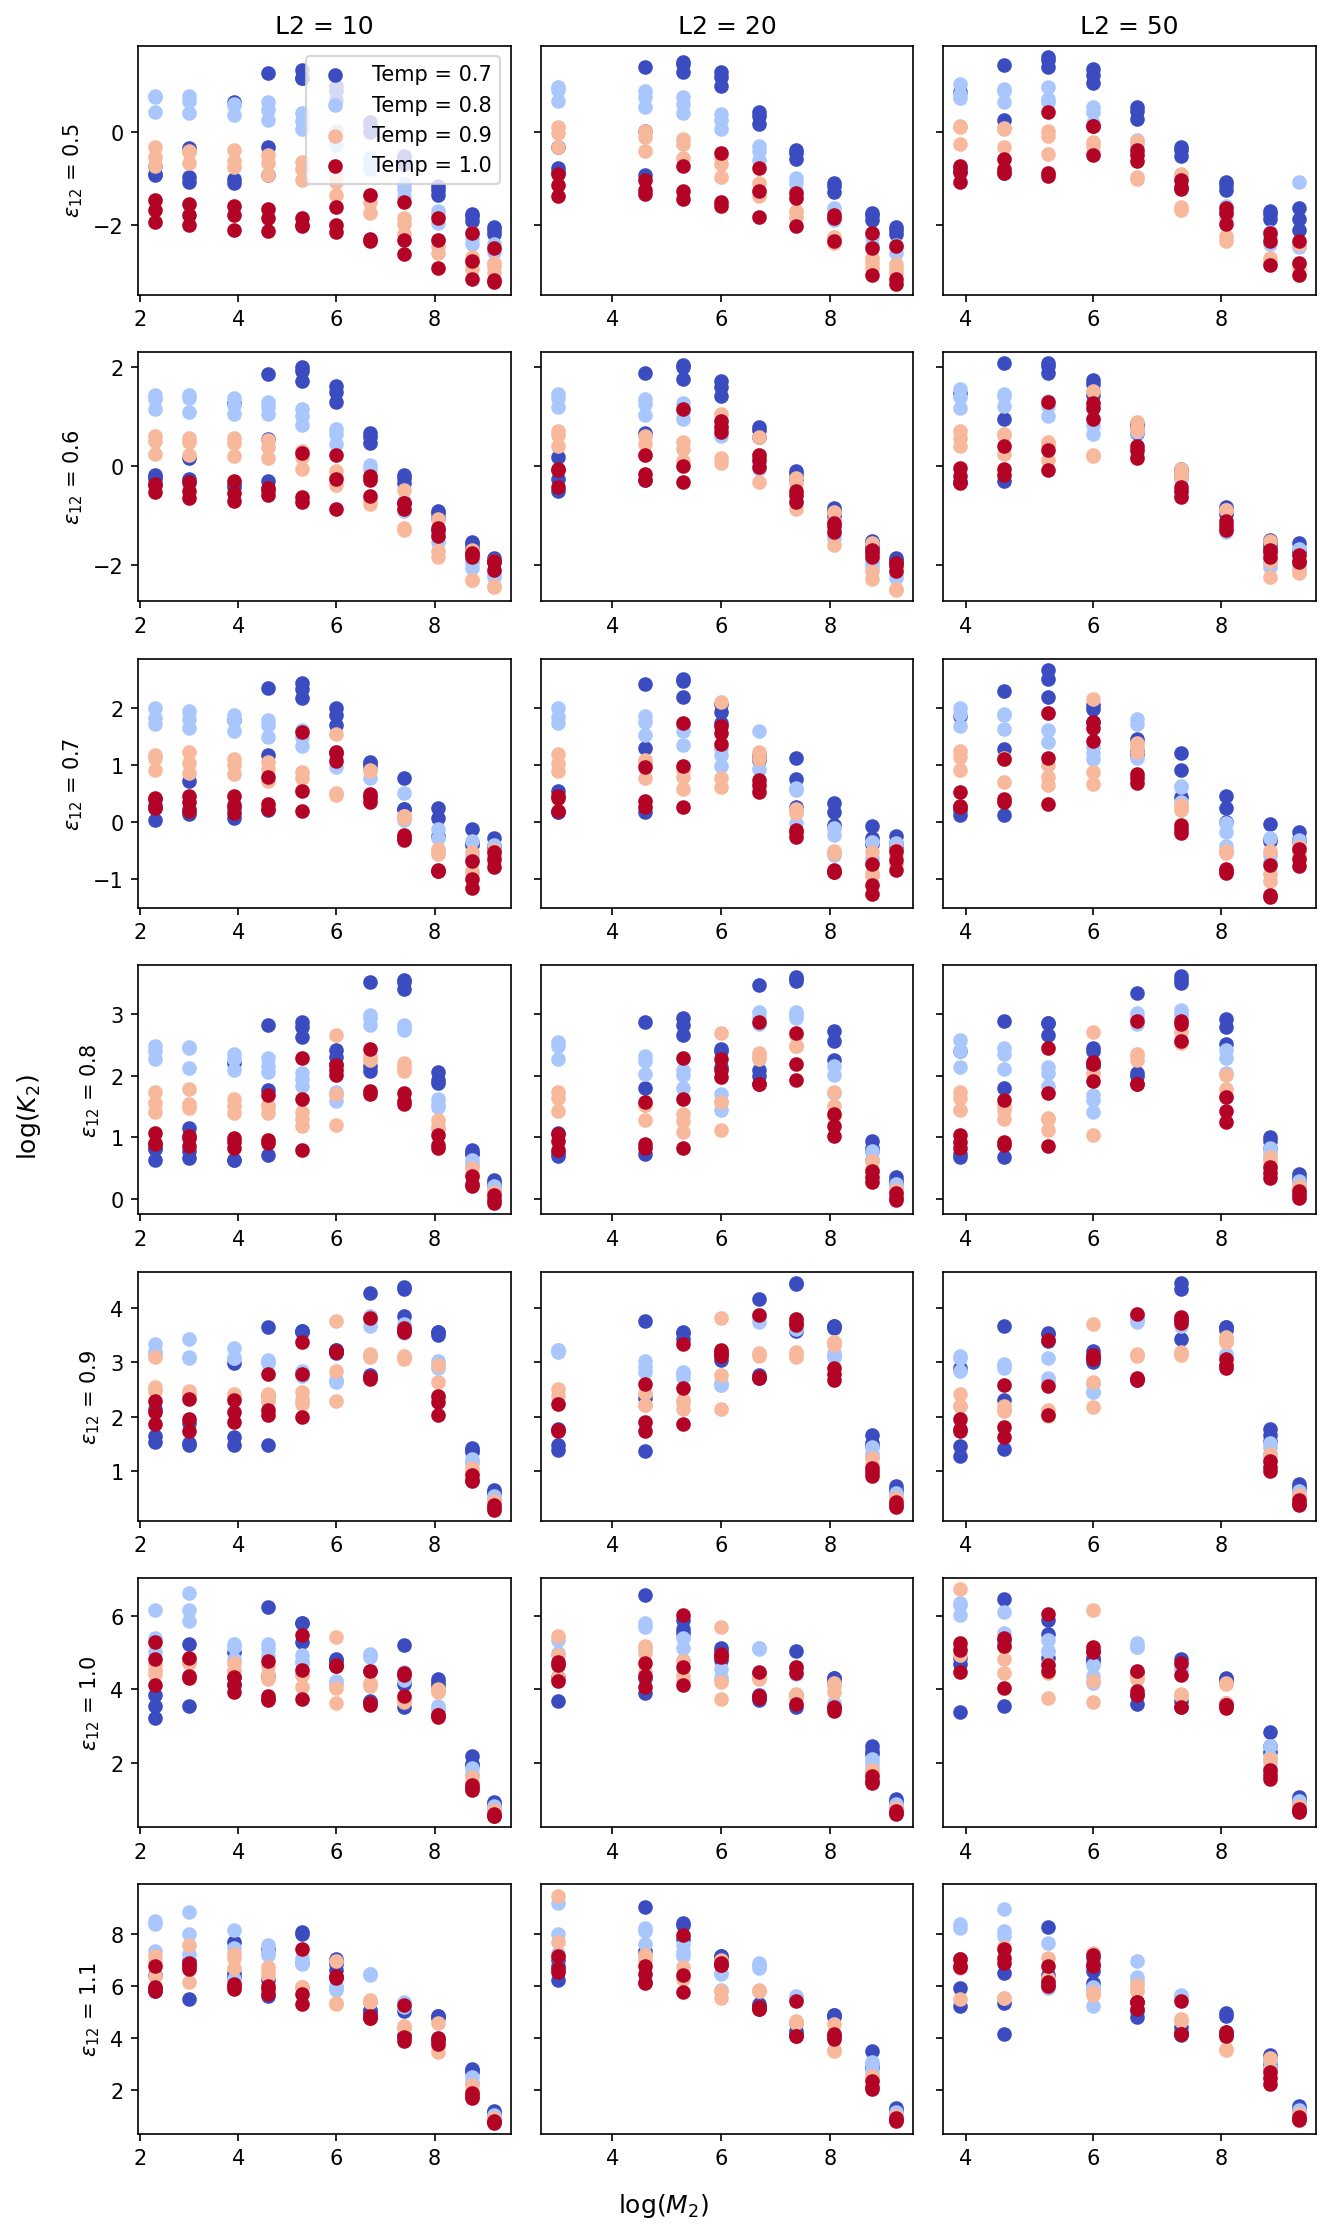

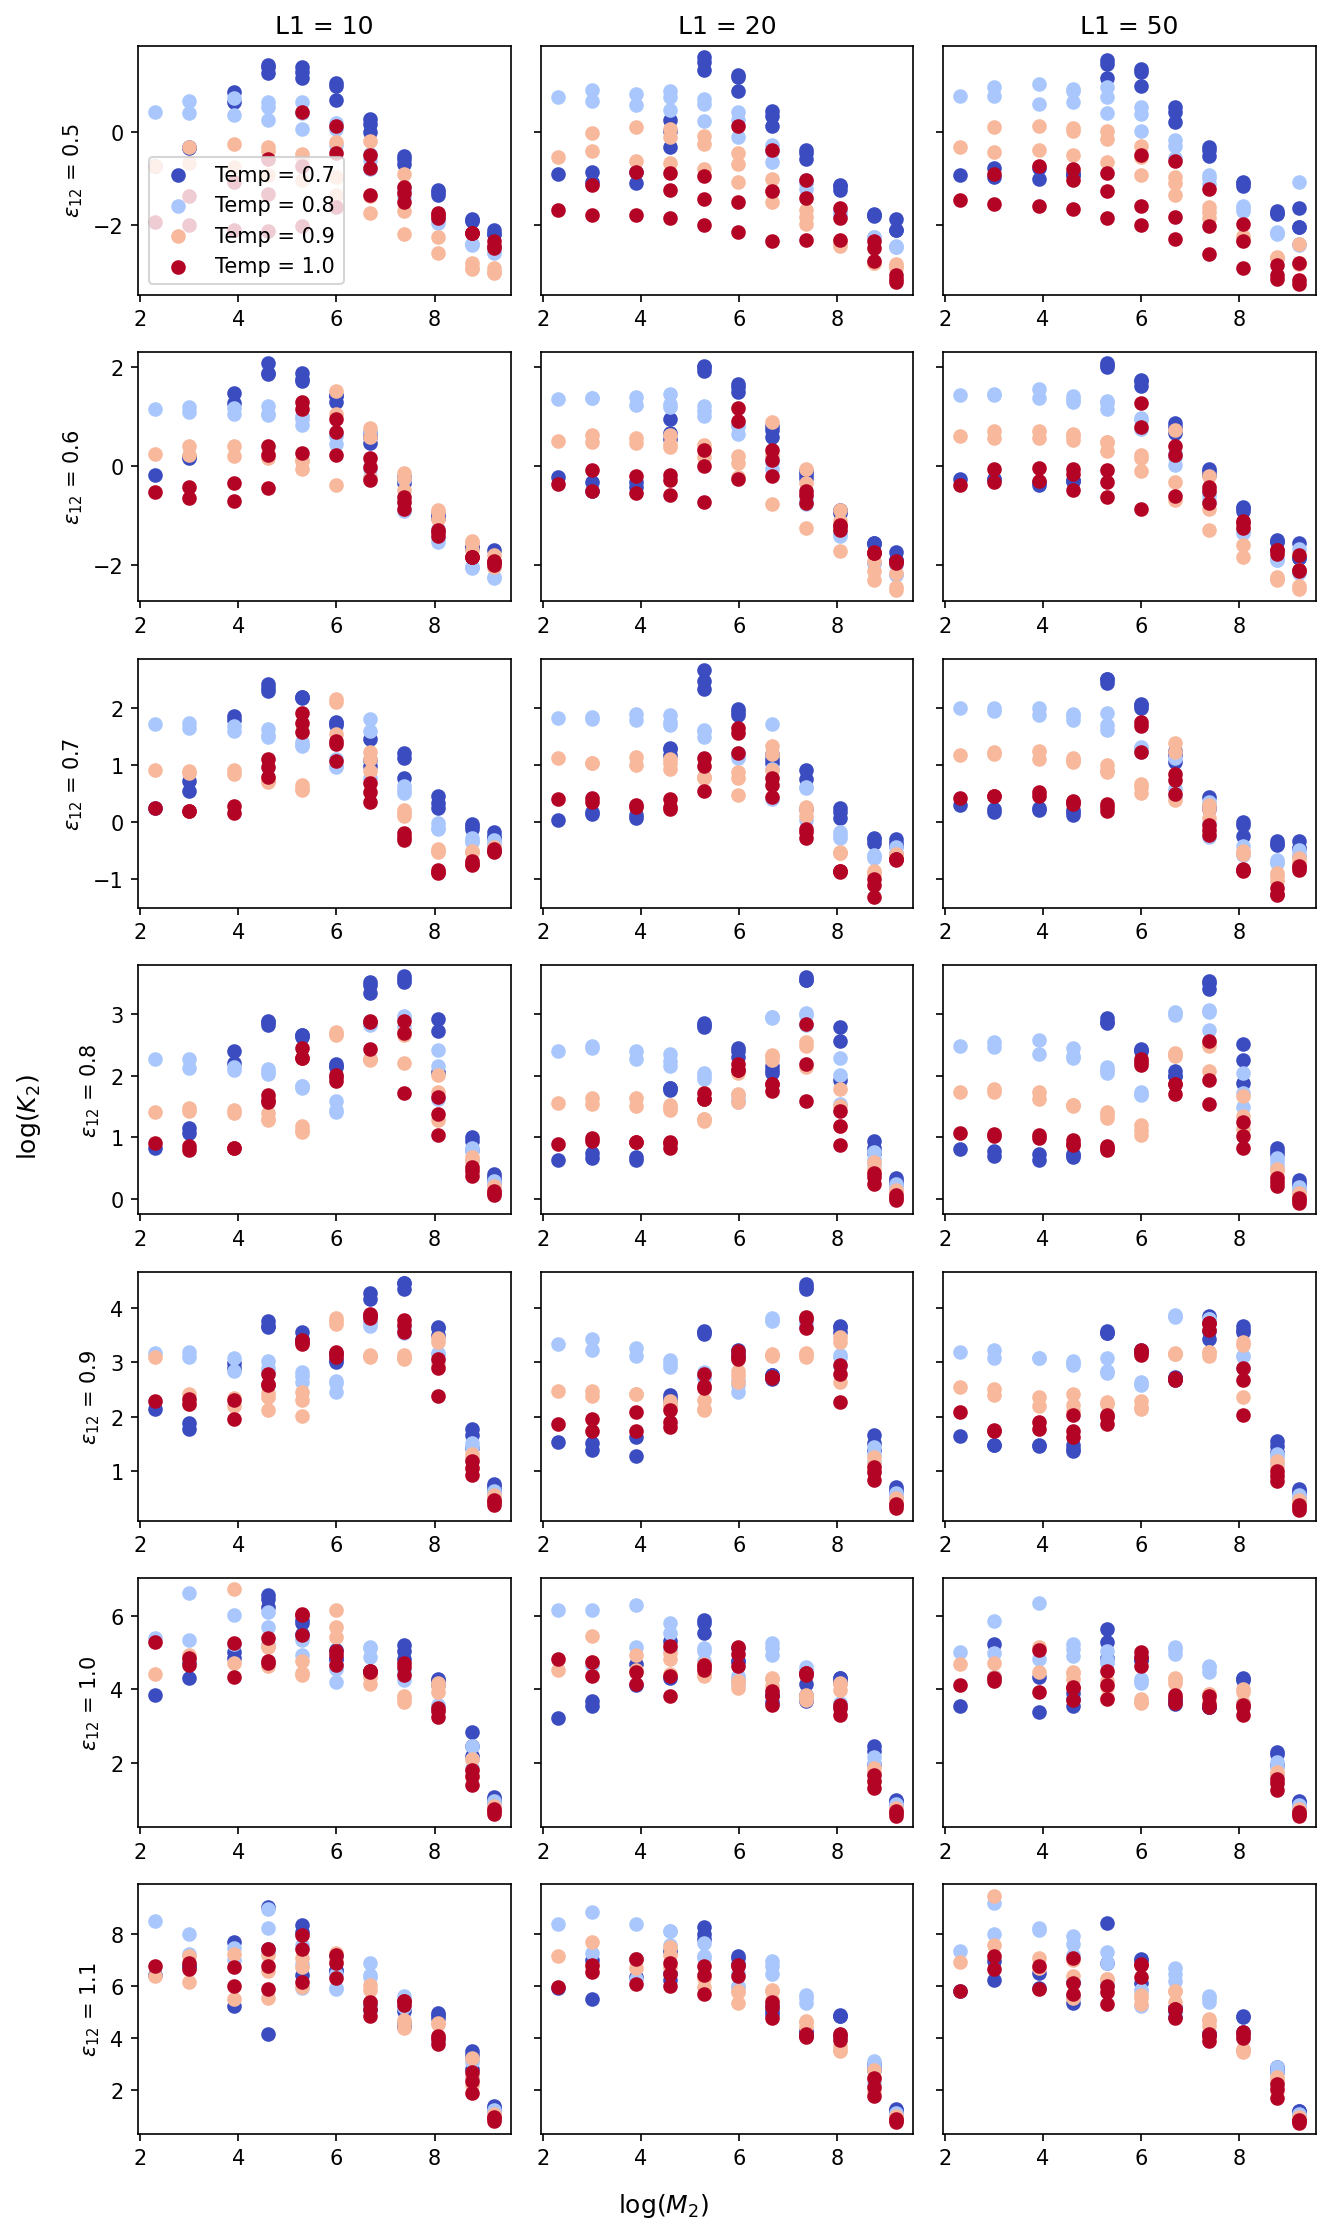

In [34]:
temperatures = [0.7, 0.8, 0.9, 1.0]
L1s = [10, 20, 50]
L2s = [10, 20, 50]
edgecols = plt.cm.coolwarm(np.linspace(0, 1, len(temperatures)))

fig1, axes1 = plt.subplots(7, 3, figsize=(9, 15), dpi=150, sharey='row')
fig2, axes2 = plt.subplots(7, 3, figsize=(9, 15), dpi=150, sharey='row')
for temp_screen, edge in zip(temperatures, edgecols):
    for i, eps in enumerate(eps12_values):
        for j, [l1, l2] in enumerate(zip(L1s, L2s)):
            ax1 = axes1[i, j]
            ax2 = axes2[i, j]
            mask1 = np.where( (temp == temp_screen) & (eps12 == eps) & (L2 == l2) )
            ax1.scatter(np.log(M2[mask1]), logK2[mask1], label=f'Temp = {temp_screen}', color=edge)
            mask2 = np.where( (temp == temp_screen) & (eps12 == eps) & (L1 == l1) )
            ax2.scatter(np.log(M2[mask2]), logK2[mask2], label=f'Temp = {temp_screen}', color=edge)
            if j == 0:
                ax1.set_ylabel(rf"$\epsilon_{{12}}$ = {eps}")
                ax2.set_ylabel(rf"$\epsilon_{{12}}$ = {eps}")
            if i == 0:
                ax1.set_title(f"L2 = {l2}")
                ax2.set_title(f"L1 = {l1}")
            if ( (i == 0) & (j == 0) ):
                ax1.legend()
                ax2.legend()
    fig1.supxlabel(r'$\log(M_2)$')
    fig1.supylabel(r'$\log(K_2)$')
    fig2.supxlabel(r'$\log(M_2)$')
    fig2.supylabel(r'$\log(K_2)$')
    fig1.tight_layout()
    fig2.tight_layout()
fig1.savefig("../2-Plots/2_2a_logM2_vs_logK2_colL2.png")
fig2.savefig("../2-Plots/2_2b_logM2_vs_logK2_colL1.png")
plt.show()